# Unit 10: CNN Tutorial, final run
The seminar asks me to read about CNNs and watch the video tutorial, look at what the network does at different layers (ReLU, intermediate and so on), and upload my own images, similar and dissimilar to the objects it was trained on, to test how it detects them.

CNN Explainer (Wang et al., 2021) runs Tiny VGG, trained on 10 classes of the Tiny ImageNet dataset: lifeboat, ladybug, pizza, bell pepper, school bus, koala, espresso, red panda, orange and sport car. This notebook loads the same trained weights from the tool's public repository (MIT licence, fixed to one commit), so that every score and layer output in my report comes from this one run. This run corrects the threshold count in my previous run, which compared the built-in examples' rounded scores with full-precision scores for my images; every comparison now uses full precision, and rounding is for display only.

## What I test
- **Reference group:** the tool's 10 built-in example images, one per class. Whether they were in the training data is not stated.
- **Trained or related class:** a synthetic sports car (a trained class) and a synthetic teacup (close to espresso, but tea is not espresso).
- **Outside the label set:** three photos of my cat, a photo of a New Year dinner table, and a synthetic wrench.

The three synthetic images were generated for this exercise; they are not photographs.

## Three ways to prepare each image
The network takes 64 × 64 pixels, so each image must be shrunk first.
1. **Centre crop, smoothed:** short side to 65 pixels with a smoothing resize, then the central 64 × 64 square (my first run's method).
2. **Padded:** the whole image fitted inside 64 × 64, with grey bars on the short sides (the method behind my earlier screenshots of 4 November).
3. **Browser-like:** short side to 65 pixels in one step without smoothing, then the central square. This approximates the resize step in the tool's own code; it does not copy the browser exactly.

No GPU is needed.

In [1]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) in Google Colab on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) in Google Colab on 12 November 2026 at 18:58 UTC


## Before the run: what I expect
The four photo expectations are the ones I wrote before my first run on 12 November. The three synthetic expectations were written on 12 November, after an earlier trial on 4 November.

In [2]:
CLASSES = ['lifeboat', 'ladybug', 'pizza', 'bell pepper', 'school bus',
           'koala', 'espresso', 'red panda', 'orange', 'sport car']
IMAGES = {
    '20230116_155823.jpg': ('cat sitting, seen from behind', 'outside the label set'),
    '20230408_101152.jpg': ('cat lying on a blanket', 'outside the label set'),
    '20230618_193855.jpg': ('cat curled in a plant pot', 'outside the label set'),
    '20251231_123241.jpg': ('New Year dinner table', 'outside the label set'),
    'synthetic_sport_car.png': ('synthetic sports car', 'trained class'),
    'synthetic_teacup.png': ('synthetic teacup', 'related class'),
    'synthetic_wrench.png': ('synthetic wrench', 'outside the label set'),
}
EXPECTED = {
    '20230116_155823.jpg': 'red panda',   # written before my first run, 12 November
    '20230408_101152.jpg': 'red panda',   # written before my first run, 12 November
    '20230618_193855.jpg': 'koala',       # written before my first run, 12 November
    '20251231_123241.jpg': 'school bus',  # written before my first run, 12 November
    'synthetic_sport_car.png': 'sport car',   # written on 12 November, after an earlier trial on 4 November
    'synthetic_teacup.png': 'espresso',       # written on 12 November, after an earlier trial on 4 November
    'synthetic_wrench.png': 'ladybug',        # written on 12 November, after an earlier trial on 4 November
}
LAYER_PHOTO = '20230408_101152.jpg'   # the image whose layers I look at in Part 4
for f, e in EXPECTED.items():
    assert e in CLASSES, f'Write the class you expect for {f} first (one of {CLASSES})'
assert LAYER_PHOTO in IMAGES
for f in IMAGES:
    print(f'{IMAGES[f][0]} ({IMAGES[f][1]}): I expect {EXPECTED[f]}')

cat sitting, seen from behind (outside the label set): I expect red panda
cat lying on a blanket (outside the label set): I expect red panda
cat curled in a plant pot (outside the label set): I expect koala
New Year dinner table (outside the label set): I expect school bus
synthetic sports car (trained class): I expect sport car
synthetic teacup (related class): I expect espresso
synthetic wrench (outside the label set): I expect ladybug


## Setting up the trained network
The weights and example images come from the CNN Explainer repository, fixed to commit d0971f9 (14 October 2023).

In [3]:
import io, json, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps
import keras
from keras import layers

BASE = 'https://raw.githubusercontent.com/poloclub/cnn-explainer/d0971f9447ed9806022a3d47587b62394682bc51/public/assets/'
def fetch(path):
    return urllib.request.urlopen(BASE + path).read()

manifest = json.loads(fetch('data/model.json'))
raw = np.frombuffer(fetch('data/group1-shard1of1.bin'), dtype='<f4')
weights, pos = {}, 0
for w in manifest['weightsManifest'][0]['weights']:
    n = int(np.prod(w['shape']))
    weights[w['name']] = raw[pos:pos + n].reshape(w['shape'])
    pos += n
assert pos == raw.size
print('Weights read:', {k: v.shape for k, v in weights.items()})

Weights read: {'conv_1_1/kernel': (3, 3, 3, 10), 'conv_1_1/bias': (10,), 'conv_1_2/kernel': (3, 3, 10, 10), 'conv_1_2/bias': (10,), 'conv_2_1/kernel': (3, 3, 10, 10), 'conv_2_1/bias': (10,), 'conv_2_2/kernel': (3, 3, 10, 10), 'conv_2_2/bias': (10,), 'output/kernel': (1690, 10), 'output/bias': (10,)}


In [4]:
# Tiny VGG as described in the repository's model.json: two blocks of two 3 x 3 convolutions with ReLU, then max pooling
model = keras.Sequential([
    keras.Input((64, 64, 3)),
    layers.Conv2D(10, 3, name='conv_1_1'), layers.Activation('relu', name='relu_1_1'),
    layers.Conv2D(10, 3, name='conv_1_2'), layers.Activation('relu', name='relu_1_2'),
    layers.MaxPooling2D(2, name='max_pool_1'),
    layers.Conv2D(10, 3, name='conv_2_1'), layers.Activation('relu', name='relu_2_1'),
    layers.Conv2D(10, 3, name='conv_2_2'), layers.Activation('relu', name='relu_2_2'),
    layers.MaxPooling2D(2, name='max_pool_2'),
    layers.Flatten(name='flatten'),
    layers.Dense(10, activation='softmax', name='output'),
])
for name in ['conv_1_1', 'conv_1_2', 'conv_2_1', 'conv_2_2', 'output']:
    model.get_layer(name).set_weights([weights[name + '/kernel'], weights[name + '/bias']])
model.summary()
every_layer = keras.Model(model.inputs, [l.output for l in model.layers])
LAYER_NAMES = [l.name for l in model.layers]
def scores(x):
    return model.predict(x[None], verbose=0)[0]

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1_1 (Conv2D)               │ (None, 62, 62, 10)     │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1_1 (Activation)           │ (None, 62, 62, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1_2 (Conv2D)               │ (None, 60, 60, 10)     │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1_2 (Activation)           │ (None, 60, 60, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool_1 (MaxPooling2D)       │ (None, 30, 30, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2_1 (Conv2D)               │ (None, 28, 28, 10)     │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2_1 (Activation)           │ (None, 28, 28, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2_2 (Conv2D)               │ (None, 26, 26, 10)     │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2_2 (Activation)           │ (None, 26, 26, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool_2 (MaxPooling2D)       │ (None, 13, 13, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1690)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │        16,910 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,920 (77.81 KB)

 Trainable params: 19,920 (77.81 KB)

 Non-trainable params: 0 (0.00 B)

## Part 1: the reference group, the tool's own examples
One example image per class, already 64 × 64, so no preparation is needed.

In [5]:
EXAMPLES = {'boat': 'lifeboat', 'bug': 'ladybug', 'pizza': 'pizza', 'pepper': 'bell pepper', 'bus': 'school bus',
            'koala': 'koala', 'espresso': 'espresso', 'panda': 'red panda', 'orange': 'orange', 'car': 'sport car'}
builtin = {}
for f, true in EXAMPLES.items():
    img = Image.open(io.BytesIO(fetch(f'img/{f}_1.jpeg'))).convert('RGB')
    assert img.size == (64, 64)
    builtin[true] = np.asarray(img, dtype='float32') / 255

def top3(p):
    order = np.argsort(p)[::-1][:3]
    return [(CLASSES[i], round(float(p[i]), 3)) for i in order]

rows = []
for true, x in builtin.items():
    p = scores(x)
    rows.append({'example': true, 'predicted': CLASSES[p.argmax()], 'score': round(float(p.max()), 3),
                 'correct': CLASSES[p.argmax()] == true, 'full_score': float(p.max())})
examples = pd.DataFrame(rows)
print(examples.drop(columns=['full_score']).to_string(index=False))
print(f"\nCorrect: {int(examples.correct.sum())} of {len(examples)}")

    example   predicted  score  correct
   lifeboat    lifeboat  0.821     True
    ladybug     ladybug  0.984     True
      pizza       pizza  0.991     True
bell pepper bell pepper  0.786     True
 school bus  school bus  0.995     True
      koala       koala  0.953     True
   espresso    espresso  0.880     True
  red panda   red panda  0.957     True
     orange      orange  0.985     True
  sport car   sport car  0.966     True

Correct: 10 of 10


## Part 2: my images, three preparations each
Upload all seven files when asked: the four photos from the `Unit10_Seminar` folder and the three synthetic images from `Unit10_Seminar/inputs/generated_originals`.

In [6]:
from google.colab import files
uploaded = files.upload()
missing = [f for f in IMAGES if f not in uploaded]
assert not missing, f'Please upload: {missing}'
originals = {f: ImageOps.exif_transpose(Image.open(io.BytesIO(uploaded[f]))).convert('RGB') for f in IMAGES}
for f, img in originals.items():
    print(f, img.size)

Saving 20230116_155823.jpg to 20230116_155823.jpg
Saving 20230408_101152.jpg to 20230408_101152.jpg
Saving 20230618_193855.jpg to 20230618_193855.jpg
Saving 20251231_123241.jpg to 20251231_123241.jpg
Saving synthetic_sport_car.png to synthetic_sport_car.png
Saving synthetic_teacup.png to synthetic_teacup.png
Saving synthetic_wrench.png to synthetic_wrench.png
20230116_155823.jpg (4032, 1816)
20230408_101152.jpg (3024, 3024)
20230618_193855.jpg (4032, 1816)
20251231_123241.jpg (4000, 1848)
synthetic_sport_car.png (1254, 1254)
synthetic_teacup.png (1254, 1254)
synthetic_wrench.png (1254, 1254)


In [7]:
def centre(img):
    """Short side to 65 pixels with Pillow's smoothing resize, then the central 64 x 64 square."""
    s = 65 / min(img.size)
    img = img.resize((max(65, round(img.width * s)), max(65, round(img.height * s))), Image.BILINEAR)
    l, t = (img.width - 64) // 2, (img.height - 64) // 2
    return np.asarray(img.crop((l, t, l + 64, t + 64)), dtype='float32') / 255

def padded(img):
    """The whole image fitted inside 64 x 64 with a smoothing resize, grey bars on the short sides."""
    s = 64 / max(img.size)
    small = img.resize((max(1, round(img.width * s)), max(1, round(img.height * s))), Image.LANCZOS)
    canvas = Image.new('RGB', (64, 64), (128, 128, 128))
    canvas.paste(small, ((64 - small.width) // 2, (64 - small.height) // 2))
    return np.asarray(canvas, dtype='float32') / 255

def browser_like(img):
    """Short side to 65 pixels in one bilinear step that reads only the 4 nearest source pixels (no smoothing), then the central square."""
    a = np.asarray(img, dtype='float32')
    s = 65 / min(img.size)
    W, H = int(img.width * s), int(img.height * s)
    xs = np.clip((np.arange(W) + 0.5) / s - 0.5, 0, img.width - 1)
    ys = np.clip((np.arange(H) + 0.5) / s - 0.5, 0, img.height - 1)
    x0, y0 = np.floor(xs).astype(int), np.floor(ys).astype(int)
    x1, y1 = np.minimum(x0 + 1, img.width - 1), np.minimum(y0 + 1, img.height - 1)
    fx, fy = (xs - x0)[None, :, None], (ys - y0)[:, None, None]
    top = a[y0][:, x0] * (1 - fx) + a[y0][:, x1] * fx
    bottom = a[y1][:, x0] * (1 - fx) + a[y1][:, x1] * fx
    out = top * (1 - fy) + bottom * fy
    l, t = (W - 64) // 2, (H - 64) // 2
    return out[t:t + 64, l:l + 64] / 255

PREPS = {'centre crop': centre, 'padded': padded, 'browser-like': browser_like}
inputs = {(f, prep): fn(originals[f]) for f in IMAGES for prep, fn in PREPS.items()}
assert all(x.shape == (64, 64, 3) for x in inputs.values())

In [8]:
rows = []
for f in IMAGES:
    for prep in PREPS:
        p = scores(inputs[(f, prep)])
        rows.append({'image': IMAGES[f][0], 'group': IMAGES[f][1], 'preparation': prep, 'I expected': EXPECTED[f],
                     'predicted': CLASSES[p.argmax()], 'score': round(float(p.max()), 3), 'top 3': top3(p)})
results = pd.DataFrame(rows)
pd.set_option('display.width', 220)
print('Main preparation (centre crop):')
print(results[results.preparation == 'centre crop'].drop(columns=['preparation']).to_string(index=False))
print('\nTop class and score under each preparation:')
wide = results.assign(result=results.predicted + ' ' + results.score.map('{:.3f}'.format))
print(wide.pivot(index='image', columns='preparation', values='result').loc[[v[0] for v in IMAGES.values()]].to_string())

Main preparation (centre crop):
                        image                 group I expected predicted  score                                                     top 3
cat sitting, seen from behind outside the label set  red panda  espresso  0.877     [(espresso, 0.877), (koala, 0.051), (ladybug, 0.031)]
       cat lying on a blanket outside the label set  red panda  espresso  0.916   [(espresso, 0.916), (red panda, 0.035), (pizza, 0.029)]
    cat curled in a plant pot outside the label set      koala  espresso  0.795 [(espresso, 0.795), (ladybug, 0.094), (red panda, 0.063)]
        New Year dinner table outside the label set school bus     koala  0.466     [(koala, 0.466), (espresso, 0.25), (lifeboat, 0.114)]
         synthetic sports car         trained class  sport car   ladybug  0.876 [(ladybug, 0.876), (bell pepper, 0.057), (orange, 0.051)]
             synthetic teacup         related class   espresso  espresso  0.974     [(espresso, 0.974), (ladybug, 0.016), (orange, 0.01)]
  

In [9]:
# How far apart are the inputs? Mean absolute difference per pixel value, on the 0 to 255 scale
rows = []
for f in IMAGES:
    c, b = inputs[(f, 'centre crop')], inputs[(f, 'browser-like')]
    rows.append({'image': IMAGES[f][0], 'centre crop vs browser-like': round(float(np.abs(c - b).mean() * 255), 1)})
print(pd.DataFrame(rows).to_string(index=False))

                        image  centre crop vs browser-like
cat sitting, seen from behind                          9.8
       cat lying on a blanket                         22.4
    cat curled in a plant pot                         22.2
        New Year dinner table                         15.7
         synthetic sports car                         14.0
             synthetic teacup                          5.3
             synthetic wrench                          8.7


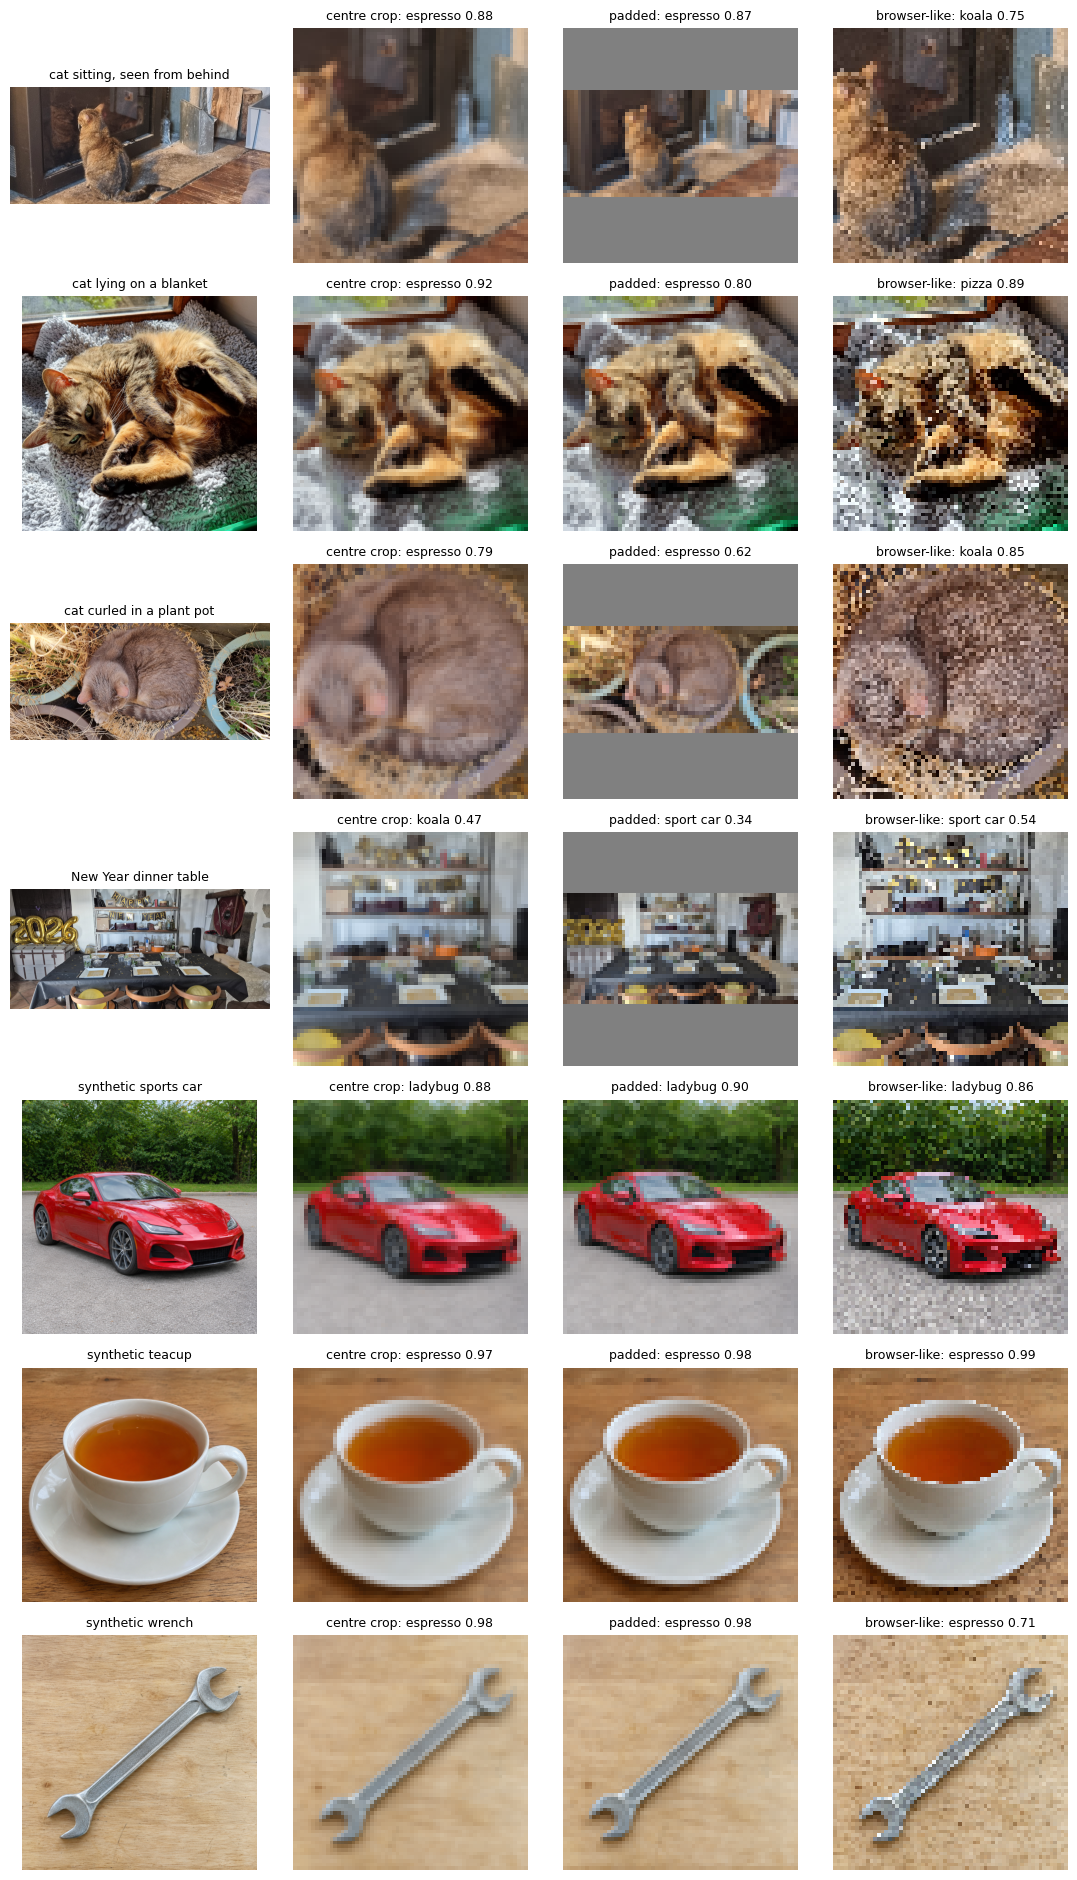

In [10]:
fig, axes = plt.subplots(len(IMAGES), 4, figsize=(11, 2.7 * len(IMAGES)))
for row, f in zip(axes, IMAGES):
    row[0].imshow(originals[f]); row[0].set_title(IMAGES[f][0], fontsize=9)
    for ax, prep in zip(row[1:], PREPS):
        p = scores(inputs[(f, prep)])
        ax.imshow(inputs[(f, prep)], interpolation='nearest')
        ax.set_title(f'{prep}: {CLASSES[p.argmax()]} {p.max():.2f}', fontsize=9)
    for ax in row: ax.axis('off')
plt.tight_layout(); plt.show()

## Part 3: would a confidence threshold help?
A simple safeguard accepts the top class only when its score reaches a threshold. For each threshold, I count how many built-in examples it keeps (they are all correct) and how many images from outside the label set it still accepts.

In [11]:
outside = [f for f in IMAGES if IMAGES[f][1] == 'outside the label set']
rows = []
for t in [0.5, 0.6, 0.7, 0.8, 0.88, 0.9, 0.95]:
    row = {'threshold': t, f'built-in kept (of {len(examples)})': int((examples.full_score >= t).sum())}   # full precision; the rounded score is for display only
    for prep in PREPS:
        row[f'outside accepted, {prep} (of {len(outside)})'] = sum(scores(inputs[(f, prep)]).max() >= t for f in outside)
    rows.append(row)
threshold = pd.DataFrame(rows)
print(threshold.to_string(index=False))
print('\nBuilt-in espresso example score:', round(float(scores(builtin['espresso']).max()), 4))

 threshold  built-in kept (of 10)  outside accepted, centre crop (of 5)  outside accepted, padded (of 5)  outside accepted, browser-like (of 5)
      0.50                     10                                     4                                4                                      5
      0.60                     10                                     4                                4                                      4
      0.70                     10                                     4                                3                                      4
      0.80                      9                                     3                                2                                      2
      0.88                      7                                     2                                1                                      1
      0.90                      7                                     2                                1                                

## Part 4: what happens at each layer
For my chosen photo (centre crop) and the tool's espresso example, the 10 maps after each layer. ReLU sets every negative value to zero, and max pooling keeps the largest value in each 2 × 2 patch.

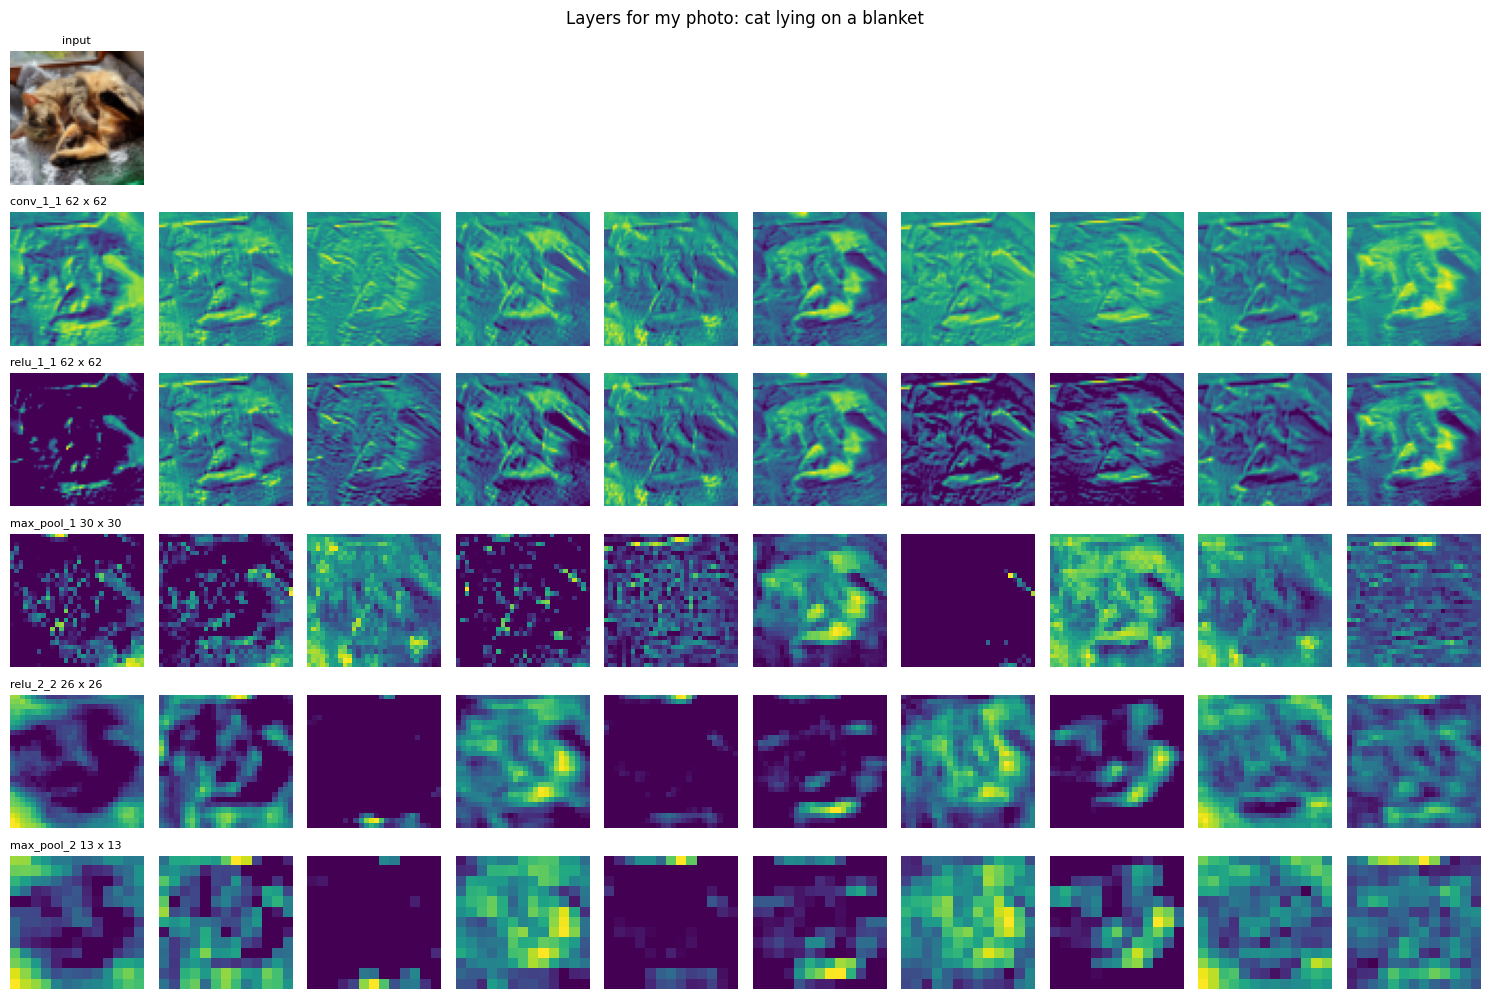

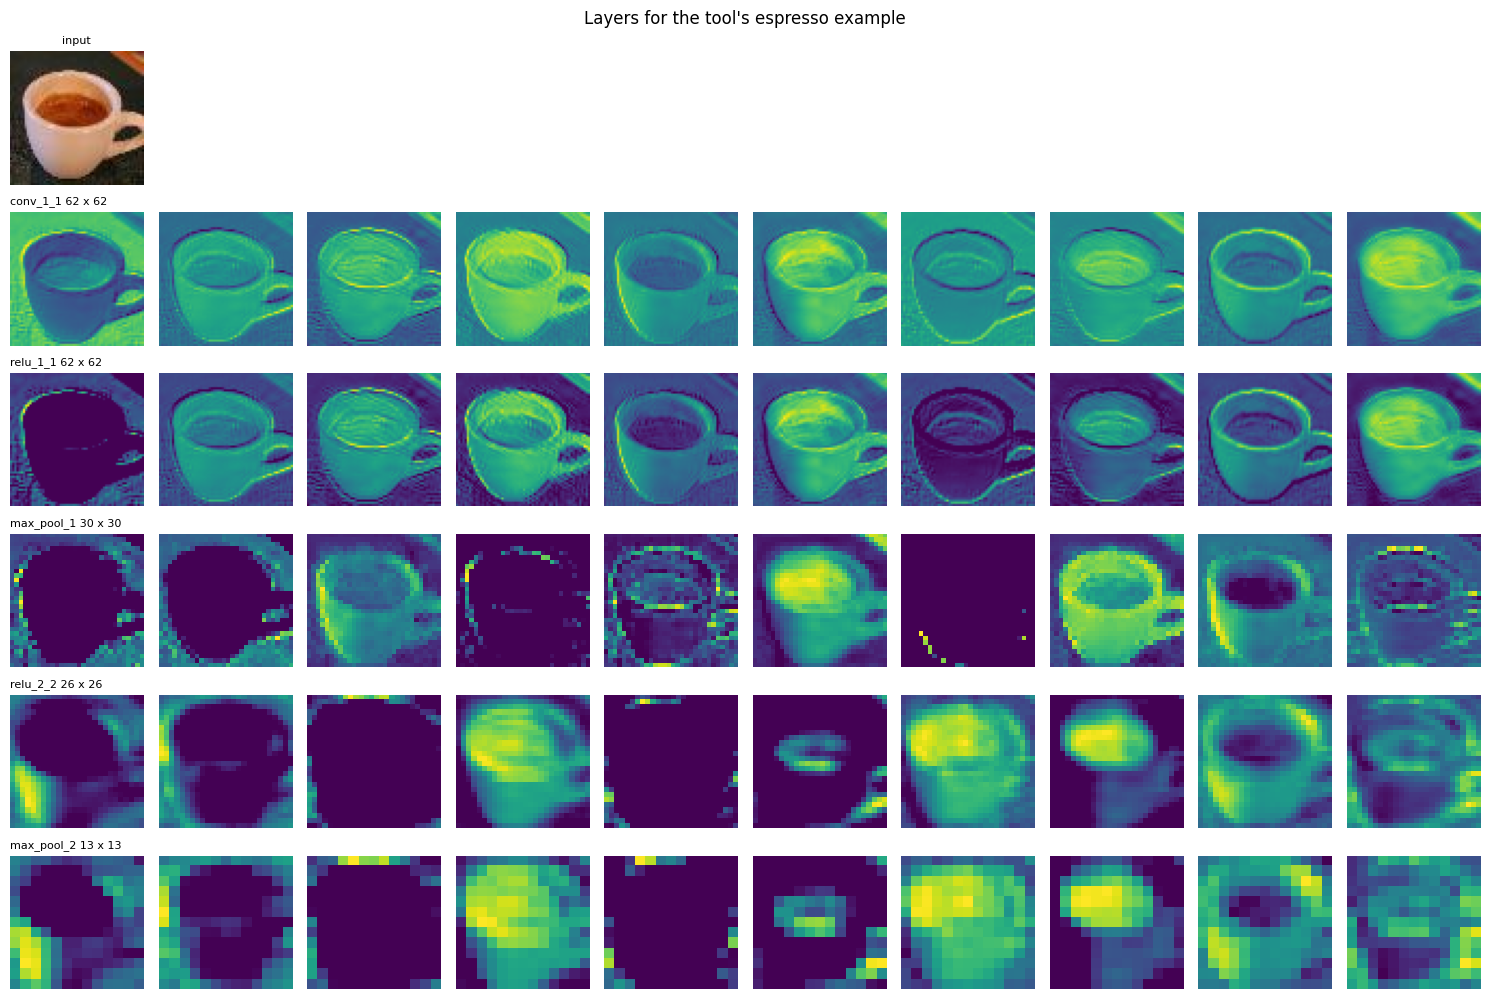

In [12]:
SHOW = ['conv_1_1', 'relu_1_1', 'max_pool_1', 'relu_2_2', 'max_pool_2']
def layer_grid(x, title):
    outs = dict(zip(LAYER_NAMES, every_layer.predict(x[None], verbose=0)))
    fig, axes = plt.subplots(len(SHOW) + 1, 10, figsize=(15, 1.7 * (len(SHOW) + 1)))
    for ax in axes.ravel(): ax.axis('off')
    axes[0, 0].imshow(x); axes[0, 0].set_title('input', fontsize=8)
    for r, name in enumerate(SHOW, start=1):
        maps = outs[name][0]
        for c in range(10):
            axes[r, c].imshow(maps[:, :, c], cmap='viridis')
        axes[r, 0].set_title(f'{name} {maps.shape[0]} x {maps.shape[1]}', fontsize=8, loc='left')
    fig.suptitle(title); plt.tight_layout(); plt.show()
layer_grid(inputs[(LAYER_PHOTO, 'centre crop')], f'Layers for my photo: {IMAGES[LAYER_PHOTO][0]}')
layer_grid(builtin['espresso'], "Layers for the tool's espresso example")

In [13]:
# Share of values above zero after each ReLU (centre crop for my images); it ignores how large the values are and where they sit
relus = ['relu_1_1', 'relu_1_2', 'relu_2_1', 'relu_2_2']
def active_share(x):
    outs = dict(zip(LAYER_NAMES, every_layer.predict(x[None], verbose=0)))
    return {r: round(float((outs[r] > 0).mean()), 3) for r in relus}
rows = [{'image': f'example: {k}', 'group': 'built-in example', **active_share(x)} for k, x in builtin.items()]
rows += [{'image': IMAGES[f][0], 'group': IMAGES[f][1], **active_share(inputs[(f, 'centre crop')])} for f in IMAGES]
active = pd.DataFrame(rows)
print(active.to_string(index=False))
print('\nAverage by group:')
print(active.groupby('group')[relus].mean().round(3).to_string())

                        image                 group  relu_1_1  relu_1_2  relu_2_1  relu_2_2
            example: lifeboat      built-in example     0.812     0.552     0.673     0.629
             example: ladybug      built-in example     0.837     0.641     0.803     0.594
               example: pizza      built-in example     0.851     0.577     0.853     0.658
         example: bell pepper      built-in example     0.900     0.429     0.823     0.496
          example: school bus      built-in example     0.814     0.715     0.814     0.680
               example: koala      built-in example     0.854     0.599     0.794     0.628
            example: espresso      built-in example     0.912     0.627     0.823     0.613
           example: red panda      built-in example     0.840     0.649     0.840     0.697
              example: orange      built-in example     0.851     0.584     0.756     0.537
           example: sport car      built-in example     0.658     0.604     0.72

## Summary of results

In [14]:
import platform, tensorflow as tf
summary = {
    'weights': 'poloclub/cnn-explainer commit d0971f9447ed9806022a3d47587b62394682bc51',
    'examples': examples.to_dict(orient='records'),
    'my_images': results.to_dict(orient='records'),
    'threshold': threshold.to_dict(orient='records'),
    'relu_active_share': active.to_dict(orient='records'),
    'layer_photo': LAYER_PHOTO,
    'versions': {'python': platform.python_version(), 'tensorflow': tf.__version__, 'keras': keras.__version__},
}
print(json.dumps(summary, indent=1, default=str))

{
 "weights": "poloclub/cnn-explainer commit d0971f9447ed9806022a3d47587b62394682bc51",
 "examples": [
  {
   "example": "lifeboat",
   "predicted": "lifeboat",
   "score": 0.821,
   "correct": true,
   "full_score": 0.8207830786705017
  },
  {
   "example": "ladybug",
   "predicted": "ladybug",
   "score": 0.984,
   "correct": true,
   "full_score": 0.9841647744178772
  },
  {
   "example": "pizza",
   "predicted": "pizza",
   "score": 0.991,
   "correct": true,
   "full_score": 0.990707516670227
  },
  {
   "example": "bell pepper",
   "predicted": "bell pepper",
   "score": 0.786,
   "correct": true,
   "full_score": 0.7857383489608765
  },
  {
   "example": "school bus",
   "predicted": "school bus",
   "score": 0.995,
   "correct": true,
   "full_score": 0.9948097467422485
  },
  {
   "example": "koala",
   "predicted": "koala",
   "score": 0.953,
   "correct": true,
   "full_score": 0.953045666217804
  },
  {
   "example": "espresso",
   "predicted": "espresso",
   "score": 0.88,

## In CNN Explainer
At https://poloclub.github.io/cnn-explainer/, click the picture with the pencil badge at the end of the example row, choose Upload, and add the three synthetic images from `inputs/generated_originals`. Take a screenshot of the overview for each, as for the photos on 12 November. The tool runs in the browser, so nothing is sent anywhere.